# HW4 A: Probing HuBERT
Train separate probes on HuBERT's 13 outputs: layer 0 is the Transformer input
after convolution, projection, and positional processing; layers 1–12 are
Transformer outputs. Freeze HuBERT. Within each task, train a separate probe per
layer using the same architecture and epoch budget. Automatic phone alignments
may contain errors.

| Task | Code | Performance | Report |
|---|---:|---:|---:|
| A1: Phonemes | 1 | 6 | 3 |
| A2: MFCCs | 1 | 6 | 3 |
| A3: Speakers | 1 | 0 | 3 |

**Total: 24 points**, plus up to 10 bonus points. Each of six implementation
checks is worth 0.5 points; probe/standardization credit is shared between A1/A2.
Performance is recomputed from saved predictions.

**Report:** use the [template](https://github.com/Louis0324/eecs183-hw4/blob/main/report_template.txt)
for one selectable-text `report.pdf` covering **A1, A2, A3, B1, C1**. Put conceptual
answers in the PDF: aim for **3–5 sentences total per section**, plus requested
figures/sequences. Retain completed answers; mark unfinished items `Not completed`.


## Setup
Save a copy in Drive, select a Colab GPU, and run cells in order. Setup and data
downloads are automatic; no Hugging Face login is needed. If pip requests a
restart, restart and rerun setup.

Implement the TODOs using their docstrings. Keep the specified top-level
function/class names and signatures. Put extra imports and constants inside
functions/classes: the grader does not execute other top-level code.

Set `SMOKE_TEST=True` in setup for a quick check. For full experiments, set it to
`False`, choose a fresh `RESULTS` folder, and rerun from setup. Save your work to
Drive or download it before the runtime ends; Colab local storage is temporary.

| Task | Implement | Full experiment |
|---|---|---|
| A1 | `Probe`, `standardize_features`, `train_phoneme_probe` | 13 layers, 5 epochs each |
| A2 | `train_mfcc_probe` | 13 layers, 50 epochs each |
| A3 | `mean_pool`, `extract_speaker_embedding` | Speaker embeddings and t-SNE for all 13 layers |

Data loading, experiment loops, plotting, and prediction export are provided.
Your training functions return `test_predictions` in the original test-row order:
integer phone IDs `[N_test]`, or MFCC values `[N_test,13]` in original target units
(`N_test=1893` for the supplied test set). Lists, NumPy arrays, and CPU tensors are
accepted. Each completed layer's predictions are saved immediately.


In [1]:
REQUIREMENTS = 'requirements.txt'
# Colab: select Runtime > Change runtime type > GPU before training.
import sys, subprocess
from pathlib import Path

# Course release settings are supplied by staff; no student login is needed.
COURSE_REPO_ID = 'Louis0324/eecs183-hw4'
COURSE_REVISION = 'hw4-2026-v4'
import os
os.environ.setdefault("HW4_HF_REPO", COURSE_REPO_ID)
os.environ.setdefault("HW4_HF_REVISION", COURSE_REVISION)

def ensure_hw4_support(repo_id=None, revision='hw4-2026-v4', packager_only=False):
    """Fetch the public support bundle, or use a local/uploaded offline copy."""
    import hashlib
    from io import BytesIO
    import json
    from pathlib import Path
    import re
    from urllib.parse import quote
    from urllib.request import urlopen
    import zipfile

    required = 'make_submission.py' if packager_only else 'course_download.py'
    if Path(required).is_file():
        return
    local_bundle = Path('hw4-student.zip')
    if local_bundle.is_file():
        content = local_bundle.read_bytes()
    elif repo_id:
        if not re.fullmatch(r'[\w.-]+/[\w.-]+', repo_id):
            raise ValueError('Expected a Hugging Face repository ID like COURSE_ORG/eecs183-hw4.')
        base = f'https://huggingface.co/datasets/{repo_id}/resolve/{quote(revision, safe="")}/'
        print('Downloading the small HW4 support bundle from Hugging Face; no login is required.')
        try:
            with urlopen(base + 'release_manifest.json', timeout=30) as response:
                manifest = json.loads(response.read(1024 * 1024))
            spec = manifest['files']['hw4-student.zip']
            if not 0 < spec['bytes'] < 30 * 1024 * 1024:
                raise ValueError('Invalid support bundle size in the release manifest.')
            with urlopen(base + 'hw4-student.zip', timeout=30) as response:
                content = response.read(spec['bytes'] + 1)
            if len(content) != spec['bytes'] or hashlib.sha256(content).hexdigest() != spec['sha256']:
                raise ValueError('Support bundle checksum mismatch; rerun to download a fresh copy.')
        except Exception as error:
            raise RuntimeError('Could not download the HW4 support release. Rerun this cell; '
                               'if needed, download hw4-student.zip from the course Hugging Face repo '
                               'and upload it through the Files sidebar before retrying.') from error
    else:
        # Allows local staff testing and offline/manual use before publication.
        try:
            from google.colab import files
        except ImportError as error:
            raise FileNotFoundError('Put hw4-student.zip in this folder or configure the course Hugging Face repository.') from error
        print('Upload hw4-student.zip to load the supplied helpers.')
        uploaded = files.upload()
        archives = [value for name, value in uploaded.items() if name.lower().endswith('.zip')]
        if len(archives) != 1:
            raise ValueError('Upload exactly one hw4-student.zip support bundle, then rerun.')
        content = archives[0]

    with zipfile.ZipFile(BytesIO(content)) as archive:
        if archive.testzip() is not None:
            raise ValueError('Corrupt support ZIP; download a fresh copy.')
        for item in archive.infolist():
            path = Path(item.filename)
            if (path.is_absolute() or '..' in path.parts or
                    ((item.external_attr >> 16) & 0o170000) == 0o120000 or
                    not path.resolve().is_relative_to(Path.cwd().resolve())):
                raise ValueError('Unsafe support archive path.')
            # Browser/local notebook edits must never be replaced by starter copies.
            if item.is_dir() or path.suffix == '.ipynb' or (packager_only and item.filename != required):
                continue
            path.parent.mkdir(parents=True, exist_ok=True)
            path.write_bytes(archive.read(item))
    if not Path(required).is_file():
        raise ValueError(f'This ZIP is missing {required}; use the current hw4-student.zip support bundle.')

ensure_hw4_support(COURSE_REPO_ID, COURSE_REVISION)
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-r', REQUIREMENTS])
import torch
print('Python:', sys.version.split()[0], 'PyTorch:', torch.__version__)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SMOKE_TEST = False  # True: only a few steps, for debugging your implementation.
DATA_ROOT = Path(os.environ.get('HW4_DATA_ROOT', 'data'))
RESULTS = Path('results'); RESULTS.mkdir(exist_ok=True)
# Checkpoints/results disappear when Colab deletes a runtime. Copy them to Drive
# or download them before disconnecting. Submission ZIPs contain no checkpoints.

Python: 3.13.16 PyTorch: 2.11.0+cu130
GPU: Tesla T4


In [2]:
# Download only Part A data; verified cached copies are reused.
from course_download import ensure_course_data
DATA_ARCHIVE = None  # Optional offline override: Path("hw4-data-a.zip")
ensure_course_data('a', data_root=DATA_ROOT, archive=DATA_ARCHIVE)


Course file: hw4-data-a.zip (226.4 MiB); cached copies are reused.


hw4-data-a.zip:   0%|          | 0.00/237M [00:00<?, ?B/s]

Prepared data: data/probes


PosixPath('data/probes')

In [3]:
import json, math, copy
import numpy as np
import torch
from torch import nn, optim
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torch.nn.utils.rnn import pad_sequence, unpad_sequence
from sklearn.metrics import accuracy_score, r2_score
import matplotlib.pyplot as plt
from hw4_runtime import load_phoneme_data, load_mfcc_data, load_audio
np.random.seed(183); torch.manual_seed(183)
device = DEVICE

## Task 1: Phoneme classification
Inputs are `[frames,768]` features; all layers share the same frames and splits.
Use a `Linear → ReLU → Linear` probe with hidden size 128. Return raw logits.
Fit standardization on training features only, train with cross entropy, select
by validation (dev) loss, and evaluate test data after choosing settings.

### Performance: A1 and A2 (6 points each)
Each layer contributes:
`(6/13) * clip((metric - baseline) / (target - baseline), 0, 1)`.
Phone baseline: **137/1893 ≈ 0.07237**; MFCC baseline: **R² = 0**.
Use accuracy fractions in this formula (35% = 0.35). Full-credit targets are below.
Missing/invalid layers earn zero only for that layer; each submitted layer must include all 1,893 test frames in order.

| HuBERT layer | Full-credit phone accuracy | Full-credit MFCC R² |
|---|---:|---:|
| 0 | 35% | 0.60 |
| 1 | 40% | 0.45 |
| 2 | 45% | 0.40 |
| 3 | 50% | 0.35 |
| 4 | 55% | 0.25 |
| 5 | 60% | 0.25 |
| 6 | 65% | 0.20 |
| 7 | 65% | 0.20 |
| 8 | 65% | 0.20 |
| 9 | 65% | 0.20 |
| 10 | 65% | 0.25 |
| 11 | 65% | 0.25 |
| 12 | 60% | 0.25 |

Export your model's predictions unchanged. Report explanations are graded
separately from model performance.


In [4]:
base_folder = DATA_ROOT / 'probes'
train_features, train_labels, dev_features, dev_labels, test_features, test_labels = load_phoneme_data(base_folder, 0)
print('Train:', train_features.shape, 'Dev:', dev_features.shape, 'Test:', test_features.shape)
print('Phone classes:', int(torch.cat([train_labels, dev_labels, test_labels]).max()) + 1)

Train: torch.Size([8000, 768]) Dev: torch.Size([1754, 768]) Test: torch.Size([1893, 768])
Phone classes: 39


In [5]:
class Probe(nn.Module):

    def __init__(self, input_dim=768, hidden_dim=128, output_dim=50):
        """Call super().__init__(); construct exactly Linear -> ReLU -> Linear using the given dimensions."""
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim),
        )
    def forward(self, x):
        """Return self.network(x)."""
        return self.network(x)

In [6]:
def standardize_features(train, dev, test, eps=1e-05):
    """Return (train_z, dev_z, test_z). Compute mean and POPULATION standard deviation (unbiased=False) per feature on train only. Clamp std to at least eps. Do not modify input tensors."""
    mean = train.mean(dim=0, keepdim=True)
    std = train.std(dim=0, unbiased=False, keepdim=True).clamp_min(eps)
    # Out-of-place ops -> inputs are untouched
    return (train - mean) / std, (dev - mean) / std, (test - mean) / std


In [7]:
def train_phoneme_probe(base_folder, layer_idx, num_epochs=10, batch_size=512, learning_rate=0.001):
    """Load the six tensors using load_phoneme_data(base_folder, layer_idx). Use standardize_features and Probe(hidden_dim=128), cross entropy, Adam, minibatches, and the supplied learning rate. Keep datasets on CPU and move batches to device. Choose a checkpoint by development loss, then evaluate test once. Return {"layer": layer_idx, "test_acc": float in [0,1], "test_predictions": predicted class IDs [N_test] in original test order}. Use max label + 1 as output size, not the number of distinct labels in one split. Honor num_epochs and batch_size."""
    import copy
    import torch
    from torch import nn
    from torch.nn import functional as F
    from torch.utils.data import TensorDataset, DataLoader
    from hw4_runtime import load_phoneme_data

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    tr_x, tr_y, dv_x, dv_y, te_x, te_y = load_phoneme_data(base_folder, layer_idx)
    tr_x, dv_x, te_x = standardize_features(tr_x.float(), dv_x.float(), te_x.float())
    tr_y, dv_y, te_y = tr_y.long(), dv_y.long(), te_y.long()

    num_classes = int(torch.cat([tr_y, dv_y, te_y]).max()) + 1
    model = Probe(input_dim=tr_x.shape[1], hidden_dim=128, output_dim=num_classes).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loader = DataLoader(TensorDataset(tr_x, tr_y), batch_size=batch_size, shuffle=True)

    def evaluate(x, y):
        model.eval()
        total, preds = 0.0, []
        with torch.no_grad():
            for i in range(0, len(x), batch_size):
                xb, yb = x[i:i + batch_size].to(device), y[i:i + batch_size].to(device)
                logits = model(xb)
                total += F.cross_entropy(logits, yb, reduction='sum').item()
                preds.append(logits.argmax(dim=1).cpu())
        return total / len(x), torch.cat(preds)

    best_loss, best_state = float('inf'), copy.deepcopy(model.state_dict())
    for _ in range(num_epochs):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = F.cross_entropy(model(xb), yb)
            loss.backward()
            optimizer.step()
        dev_loss, _ = evaluate(dv_x, dv_y)
        if dev_loss < best_loss:
            best_loss, best_state = dev_loss, copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    _, test_preds = evaluate(te_x, te_y)  # test evaluated once, in original order
    test_acc = (test_preds == te_y).float().mean().item()
    return {"layer": layer_idx, "test_acc": float(test_acc), "test_predictions": test_preds}

{'layer': 0, 'test_acc': 0.4738510251045227}
{'layer': 1, 'test_acc': 0.5472794771194458}
{'layer': 2, 'test_acc': 0.5747490525245667}
{'layer': 3, 'test_acc': 0.6133121848106384}
{'layer': 4, 'test_acc': 0.6513470411300659}
{'layer': 5, 'test_acc': 0.7321711778640747}
{'layer': 6, 'test_acc': 0.7654516696929932}
{'layer': 7, 'test_acc': 0.7860538959503174}
{'layer': 8, 'test_acc': 0.7892234325408936}
{'layer': 9, 'test_acc': 0.7860538959503174}
{'layer': 10, 'test_acc': 0.7923930287361145}
{'layer': 11, 'test_acc': 0.7929213047027588}
{'layer': 12, 'test_acc': 0.7390385866165161}


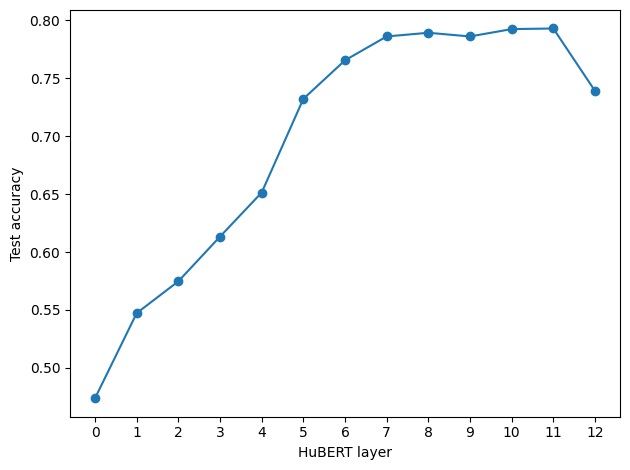

In [8]:
from probe_submission import save_probe_predictions
all_results = []
for layer_idx in ([0] if SMOKE_TEST else range(13)):
    result = train_phoneme_probe(base_folder, layer_idx, num_epochs=1 if SMOKE_TEST else 5, batch_size=256)
    save_probe_predictions('phoneme', result, RESULTS / 'a')
    result = {key: value for key, value in result.items() if key != 'test_predictions'}
    all_results.append(result)
    print(result)
    (RESULTS / 'a').mkdir(exist_ok=True)
    (RESULTS / 'a/phoneme_results.json').write_text(json.dumps(all_results, indent=2))
fig, ax = plt.subplots()
ax.plot([r['layer'] for r in all_results], [r['test_acc'] for r in all_results], marker='o')
ax.set(xlabel='HuBERT layer', ylabel='Test accuracy', xticks=range(13))
fig.tight_layout(); fig.savefig(RESULTS / 'a/phoneme_accuracy.png', dpi=150)
plt.show()

### Report A1: Phoneme probing (3 points)
In **A1** of `report.pdf`:

- **Figure A1 (1 point):** test accuracy versus all 13 layers, with labeled axes.
  Mark missing or smoke-only results.
- **Answer A1 (2 points):** identify the best observed layer, interpret the
  phonetic-information trend, and give one limitation of the probe or alignments.

Record your training budget in the report summary. Low accuracy alone does not
reduce report credit.


## Task 2: MFCC regression
Predict 13 MFCC coefficients describing each audio frame's spectral envelope.
Use the same probe architecture with 13 unrestricted real outputs, training-only
input standardization, and MSE loss. Evaluate with **uniform-average R²** across the
13 coefficients; negative R² is valid.

Use 50 epochs per layer by default and select checkpoints by validation loss.
Report any smaller budget you use. Performance follows the table above.


In [10]:
def train_mfcc_probe(base_folder, layer_idx, num_epochs=10, batch_size=512, learning_rate=0.001):
    """Load the six tensors with load_mfcc_data. Train Probe(input_dim, 128, output_dim=13) using standardize_features, MSE and Adam. Choose a checkpoint by development loss. Return {"layer": layer_idx, "overall_r2": float, "test_predictions": predicted MFCCs [N_test,13] in original test order}, using sklearn.metrics.r2_score(test_targets, predictions, multioutput="uniform_average"). Keep minibatches small and honor the arguments."""
    import copy
    import torch
    from torch.nn import functional as F
    from torch.utils.data import TensorDataset, DataLoader
    from sklearn.metrics import r2_score
    from hw4_runtime import load_mfcc_data

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    tr_x, tr_y, dv_x, dv_y, te_x, te_y = load_mfcc_data(base_folder, layer_idx)
    tr_x, dv_x, te_x = standardize_features(tr_x.float(), dv_x.float(), te_x.float())
    tr_y, dv_y, te_y = tr_y.float(), dv_y.float(), te_y.float()

    # Target standardization (train stats only); predictions are un-standardized at the end
    y_mean = tr_y.mean(dim=0, keepdim=True)
    y_std = tr_y.std(dim=0, unbiased=False, keepdim=True).clamp_min(1e-5)
    tr_yz, dv_yz = (tr_y - y_mean) / y_std, (dv_y - y_mean) / y_std

    out_dim = tr_y.shape[1]  # 13
    model = Probe(input_dim=tr_x.shape[1], hidden_dim=128, output_dim=out_dim).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loader = DataLoader(TensorDataset(tr_x, tr_yz), batch_size=batch_size, shuffle=True)

    def predict(x):
        model.eval()
        outs = []
        with torch.no_grad():
            for i in range(0, len(x), batch_size):
                outs.append(model(x[i:i + batch_size].to(device)).cpu())
        return torch.cat(outs)

    best_loss, best_state = float('inf'), copy.deepcopy(model.state_dict())
    for _ in range(num_epochs):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = F.mse_loss(model(xb), yb)
            loss.backward()
            optimizer.step()
        dev_loss = F.mse_loss(predict(dv_x), dv_yz).item()
        if dev_loss < best_loss:
            best_loss, best_state = dev_loss, copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    test_preds = predict(te_x) * y_std + y_mean  # back to original MFCC units
    overall_r2 = r2_score(te_y.numpy(), test_preds.numpy(), multioutput="uniform_average")
    return {"layer": layer_idx, "overall_r2": float(overall_r2), "test_predictions": test_preds}

{'layer': 0, 'overall_r2': 0.798969030380249}
{'layer': 1, 'overall_r2': 0.729068398475647}
{'layer': 2, 'overall_r2': 0.7008359432220459}
{'layer': 3, 'overall_r2': 0.6457837820053101}
{'layer': 4, 'overall_r2': 0.5864492654800415}
{'layer': 5, 'overall_r2': 0.5334679484367371}
{'layer': 6, 'overall_r2': 0.47624698281288147}
{'layer': 7, 'overall_r2': 0.44640710949897766}
{'layer': 8, 'overall_r2': 0.4246913492679596}
{'layer': 9, 'overall_r2': 0.42645174264907837}
{'layer': 10, 'overall_r2': 0.4544755220413208}
{'layer': 11, 'overall_r2': 0.49418866634368896}
{'layer': 12, 'overall_r2': 0.5082005858421326}


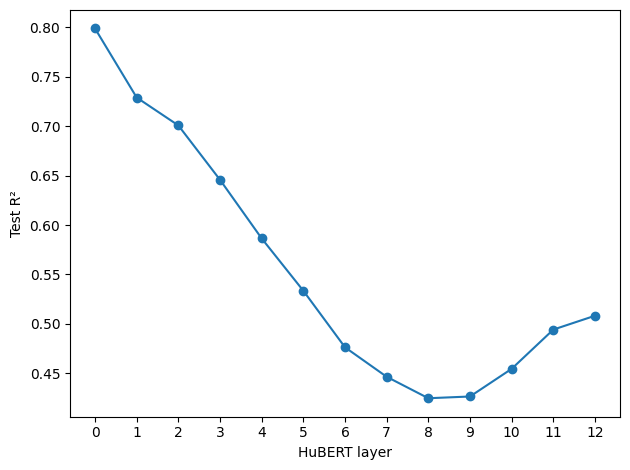

In [11]:
from probe_submission import save_probe_predictions
mfcc_all_results = []
for layer_idx in ([0] if SMOKE_TEST else range(13)):
    result = train_mfcc_probe(base_folder, layer_idx, num_epochs=1 if SMOKE_TEST else 50, batch_size=256)
    save_probe_predictions('mfcc', result, RESULTS / 'a')
    result = {key: value for key, value in result.items() if key != 'test_predictions'}
    mfcc_all_results.append(result)
    print(result)
    (RESULTS / 'a').mkdir(exist_ok=True)
    (RESULTS / 'a/mfcc_results.json').write_text(json.dumps(mfcc_all_results, indent=2))
fig, ax = plt.subplots()
ax.plot([r['layer'] for r in mfcc_all_results], [r['overall_r2'] for r in mfcc_all_results], marker='o')
ax.set(xlabel='HuBERT layer', ylabel='Test R²', xticks=range(13))
fig.tight_layout(); fig.savefig(RESULTS / 'a/mfcc_r2.png', dpi=150)
plt.show()

### Report A2: MFCC probing (3 points)
In **A2** of `report.pdf`:

- **Figure A2 (1 point):** uniform-average test R² versus all 13 layers, with
  labeled axes. Keep negative values and mark unfinished layers.
- **Answer A2 (2 points):** identify the best observed layer, explain layer 0,
  and compare this acoustic trend with the phoneme trend in A1.


## Task 3: Speaker embeddings
The supplied data contains 20 speakers × 50 recordings. Run frozen HuBERT in
evaluation mode and mean-pool valid frames. Return `[768]` for one layer or
`[13,768]` for all layers. Use the same recordings across layers; the provided
t-SNE plotter fixes the seed and uses perplexity below the recording count.


In [12]:
def mean_pool(hidden_states, lengths):
    """hidden_states is [B,T,D], lengths is [B] with positive valid-frame counts. Return [B,D], averaging only frames t < lengths[b]. Preserve gradients and device."""
    import torch
    B, T, D = hidden_states.shape
    lengths = torch.as_tensor(lengths, device=hidden_states.device)
    mask = (torch.arange(T, device=hidden_states.device)[None, :] < lengths[:, None])
    mask = mask.to(hidden_states.dtype).unsqueeze(-1)            # [B,T,1]
    summed = (hidden_states * mask).sum(dim=1)                    # [B,D]
    counts = mask.sum(dim=1).clamp_min(1.0)                       # [B,1]
    return summed / counts

In [13]:
from transformers import HubertModel, Wav2Vec2FeatureExtractor
from sklearn.manifold import TSNE
import os
from hw4_runtime import load_hubert
hubert = load_hubert().to(device).eval()
# Original speaker dataset: 20 speakers, 50 recordings each (about 215 MiB).
from course_download import ensure_course_data
ensure_course_data("speakers", data_root=DATA_ROOT)
audio_files = sorted((DATA_ROOT / 'speakers').rglob('*.flac'))
if not audio_files:
    raise FileNotFoundError('Speaker download is incomplete; rerun this cell.')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/378M [00:00<?, ?B/s]

Course file: hw4-speakers.zip (214.6 MiB); cached copies are reused.


hw4-speakers.zip:   0%|          | 0.00/225M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/378M [00:00<?, ?B/s]

Prepared data: data/speakers


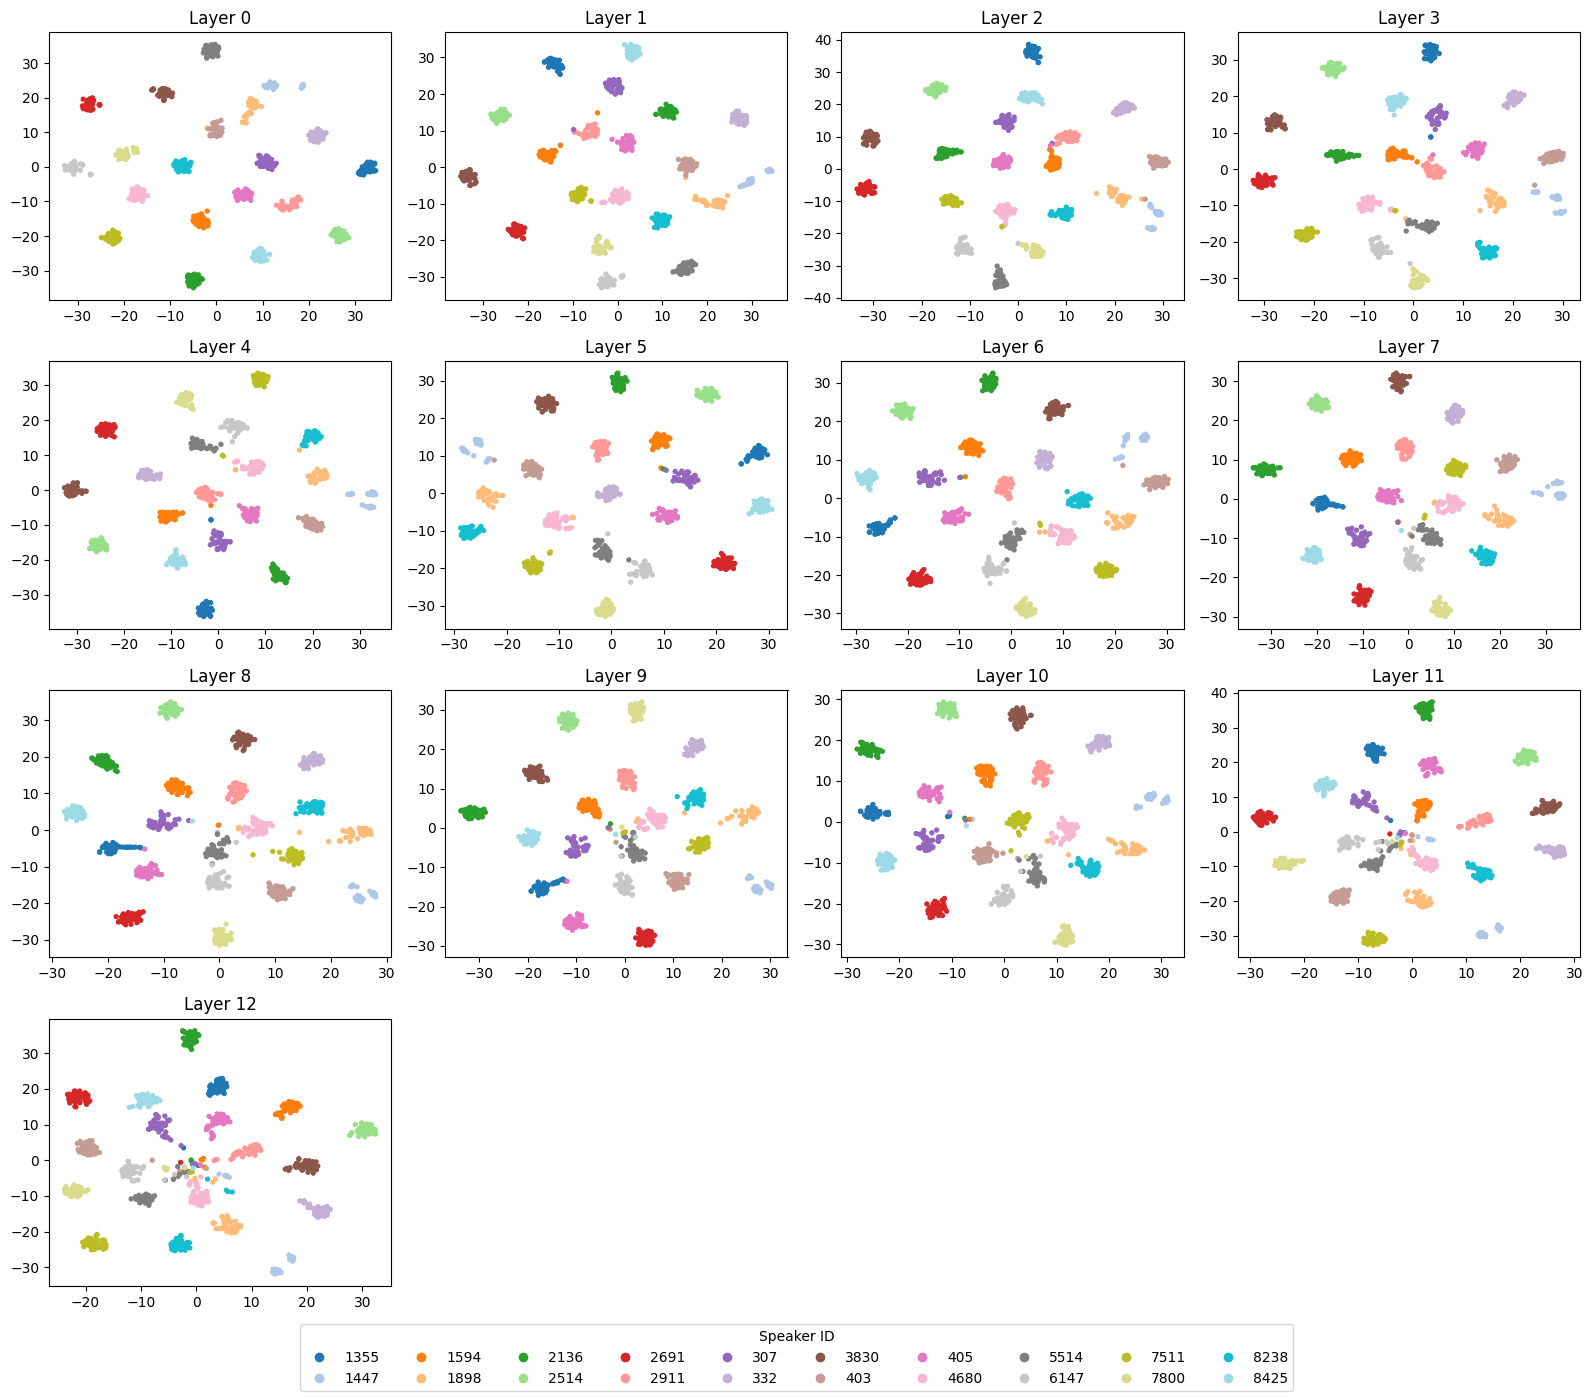

In [14]:
def extract_speaker_embedding(audio_path, model, feature_extractor=None, layer_idx=0):
    """Return [768] for one layer, or [13,768] when layer_idx=None.
    Use load_audio, normalize the mono 16 kHz waveform, model.eval(), and
    torch.no_grad(). Request output_hidden_states=True, then mean_pool.
    Returning every layer from one forward pass saves substantial compute.
    """
    import numpy as np
    import torch
    from hw4_runtime import load_audio

    out = load_audio(audio_path)
    sr = None
    if isinstance(out, (tuple, list)):
        wav, sr = out[0], (out[1] if len(out) > 1 else None)
    else:
        wav = out
    wav = torch.as_tensor(np.asarray(wav), dtype=torch.float32)
    if wav.dim() > 1:  # make mono
        wav = wav.mean(dim=0) if wav.shape[0] < wav.shape[-1] else wav.mean(dim=-1)
    if sr is not None and int(sr) != 16000:
        import torchaudio
        wav = torchaudio.functional.resample(wav, int(sr), 16000)

    if feature_extractor is not None:
        input_values = feature_extractor(wav.numpy(), sampling_rate=16000,
                                         return_tensors='pt').input_values[0]
    else:
        # Zero-mean / unit-variance normalization
        input_values = (wav - wav.mean()) / torch.sqrt(wav.var(unbiased=False) + 1e-7)

    model.eval()
    device = next(model.parameters()).device
    with torch.no_grad():
        outputs = model(input_values.unsqueeze(0).to(device), output_hidden_states=True)
        hs = outputs.hidden_states                     # tuple of 13 x [1,T,768]
        T = hs[0].shape[1]
        lengths = torch.tensor([T], device=device)
        if layer_idx is None:
            pooled = torch.stack([mean_pool(h, lengths)[0] for h in hs])   # [13,768]
        else:
            pooled = mean_pool(hs[layer_idx], lengths)[0]                   # [768]
    return pooled.cpu()


# All layers are collected together. Speaker ID is the first filename component.
selected = audio_files[::max(1, len(audio_files) // 8)][:8] if SMOKE_TEST else audio_files
embeddings, speaker_ids = [], []
for path in selected:
    embeddings.append(extract_speaker_embedding(path, hubert, layer_idx=None))
    speaker_ids.append(Path(path).stem.split('-')[0])
embeddings = torch.stack(embeddings).cpu().numpy()
labels = np.array([sorted(set(speaker_ids)).index(s) for s in speaker_ids])
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
for layer, ax in enumerate(axes.flat):
    if layer >= 13:
        ax.axis('off'); continue
    xy = TSNE(n_components=2, random_state=183, init='pca', learning_rate='auto',
              perplexity=min(30, len(selected)-1), max_iter=500).fit_transform(embeddings[:, layer])
    ax.scatter(xy[:, 0], xy[:, 1], c=labels, cmap='tab20', s=8)
    ax.set_title(f'Layer {layer}')
from matplotlib.lines import Line2D
speakers = sorted(set(speaker_ids))
handles = [Line2D([], [], marker='o', linestyle='', color=plt.get_cmap('tab20')(i / max(1, len(speakers)-1)), label=s)
           for i, s in enumerate(speakers)]
fig.legend(handles=handles, loc='lower center', ncol=10, title='Speaker ID')
fig.tight_layout(rect=(0, 0.05, 1, 1))
(RESULTS / 'a').mkdir(exist_ok=True)
fig.savefig(RESULTS / 'a/speakers.png', dpi=150)
plt.show()


### Report A3: Speaker analysis (3 points)
In **A3** of `report.pdf`:

- **Figure A3 (1 point):** all 13 t-SNE panels, with layer labels, speaker legend,
  and seed/perplexity in the caption.
- **Answer A3 (2 points):** identify the clearest speaker separation, relate it
  to A1/A2, and explain one limitation of t-SNE. Distances across separate plots
  are not directly comparable.

### Optional bonus: your voice (up to 10 points)
Use **two microphones in the same three environments**. Record five different
sentences per microphone/environment combination: **2 × 3 × 5 = 30 recordings**.
Mean-pool your HuBERT embeddings and add the groups to one speaker plot at a
layer of your choice.
In **BONUS** of the PDF, include:

- Labeled plot and recording setup/layer (6 points).
- Comparison with other speakers (2 points).
- Comparison among your six groups, including microphone/environment effects (2 points).

Submit the figure and explanation; keep personal audio out of the ZIP.


## Prepare your submission
The final cell packages your current notebook, available predictions/plots, and
**one shared `report.pdf`**. Checkpoints, datasets, and audio are excluded.
Combine separate reports into one PDF before uploading.

1. Run the final cell. Upload your current combined `report.pdf`, or cancel if
   it is not ready. Save the download as **`hw4-a.zip`**.
2. For A only, submit this ZIP to Gradescope. To continue, upload it at B's
   earlier-ZIP prompt, save B's result as `hw4-ab.zip`, and import that ZIP in C.

**Partial work is accepted:** completed questions are graded independently.
Check the printed file list and your PDF before uploading. Every Gradescope
resubmission must contain **all** work you want graded.

**Another order or runtime reset:** set `include_previous=True` and import your
latest ZIP in whichever notebook you package last. The final cell needs no
training/setup or GPU. To include results saved on Drive, mount Drive and set
`RESULTS` to that folder's path before packaging.

Saved predictions: `RESULTS/a/phoneme_layer_*.json` and
`RESULTS/a/mfcc_layer_*.json`, layers 0–12. Plots alone do not earn performance credit.


In [ ]:
include_report = False  # Upload one combined PDF, or cancel to keep an imported/saved PDF.
include_previous = False  # Merge earlier submission ZIPs; cancel if none.

# Packaging needs no training dependencies, GPU, or data download.
# Course release settings are supplied by staff; no student login is needed.
COURSE_REPO_ID = 'Louis0324/eecs183-hw4'
COURSE_REVISION = 'hw4-2026-v4'
import os
os.environ.setdefault("HW4_HF_REPO", COURSE_REPO_ID)
os.environ.setdefault("HW4_HF_REVISION", COURSE_REVISION)

def ensure_hw4_support(repo_id=None, revision='hw4-2026-v4', packager_only=False):
    """Fetch the public support bundle, or use a local/uploaded offline copy."""
    import hashlib
    from io import BytesIO
    import json
    from pathlib import Path
    import re
    from urllib.parse import quote
    from urllib.request import urlopen
    import zipfile

    required = 'make_submission.py' if packager_only else 'course_download.py'
    if Path(required).is_file():
        return
    local_bundle = Path('hw4-student.zip')
    if local_bundle.is_file():
        content = local_bundle.read_bytes()
    elif repo_id:
        if not re.fullmatch(r'[\w.-]+/[\w.-]+', repo_id):
            raise ValueError('Expected a Hugging Face repository ID like COURSE_ORG/eecs183-hw4.')
        base = f'https://huggingface.co/datasets/{repo_id}/resolve/{quote(revision, safe="")}/'
        print('Downloading the small HW4 support bundle from Hugging Face; no login is required.')
        try:
            with urlopen(base + 'release_manifest.json', timeout=30) as response:
                manifest = json.loads(response.read(1024 * 1024))
            spec = manifest['files']['hw4-student.zip']
            if not 0 < spec['bytes'] < 30 * 1024 * 1024:
                raise ValueError('Invalid support bundle size in the release manifest.')
            with urlopen(base + 'hw4-student.zip', timeout=30) as response:
                content = response.read(spec['bytes'] + 1)
            if len(content) != spec['bytes'] or hashlib.sha256(content).hexdigest() != spec['sha256']:
                raise ValueError('Support bundle checksum mismatch; rerun to download a fresh copy.')
        except Exception as error:
            raise RuntimeError('Could not download the HW4 support release. Rerun this cell; '
                               'if needed, download hw4-student.zip from the course Hugging Face repo '
                               'and upload it through the Files sidebar before retrying.') from error
    else:
        # Allows local staff testing and offline/manual use before publication.
        try:
            from google.colab import files
        except ImportError as error:
            raise FileNotFoundError('Put hw4-student.zip in this folder or configure the course Hugging Face repository.') from error
        print('Upload hw4-student.zip to load the supplied helpers.')
        uploaded = files.upload()
        archives = [value for name, value in uploaded.items() if name.lower().endswith('.zip')]
        if len(archives) != 1:
            raise ValueError('Upload exactly one hw4-student.zip support bundle, then rerun.')
        content = archives[0]

    with zipfile.ZipFile(BytesIO(content)) as archive:
        if archive.testzip() is not None:
            raise ValueError('Corrupt support ZIP; download a fresh copy.')
        for item in archive.infolist():
            path = Path(item.filename)
            if (path.is_absolute() or '..' in path.parts or
                    ((item.external_attr >> 16) & 0o170000) == 0o120000 or
                    not path.resolve().is_relative_to(Path.cwd().resolve())):
                raise ValueError('Unsafe support archive path.')
            # Browser/local notebook edits must never be replaced by starter copies.
            if item.is_dir() or path.suffix == '.ipynb' or (packager_only and item.filename != required):
                continue
            path.parent.mkdir(parents=True, exist_ok=True)
            path.write_bytes(archive.read(item))
    if not Path(required).is_file():
        raise ValueError(f'This ZIP is missing {required}; use the current hw4-student.zip support bundle.')

ensure_hw4_support(COURSE_REPO_ID, COURSE_REVISION, packager_only=True)
try:
    from google.colab import files as colab_files
except ImportError:
    colab_files = None
from make_submission import build_submission, from_colab
if colab_files is not None:
    from_colab('a', include_report=include_report, include_previous=include_previous,
               results_dir=globals().get("RESULTS", "results"))
else:
    build_submission(report="report.pdf" if include_report else None)
